# تشخیص ناهنجاری در لاگ سرورها (Log Anomaly Detection)

پایپ‌لاین کامل و بدون‌نظارت با **Isolation Forest** و **Autoencoder**:

لاگ خام ← پارس ← استخراج الگو (Template) ← پنجره‌های ۱ دقیقه‌ای ← بردار ویژگی ← مدل ← امتیاز ناهنجاری

همه‌ی کدها در همین یک فایل است و به دیتاست خارجی نیاز ندارد (لاگ مصنوعی تولید می‌شود).

## ۱) نصب و ایمپورت کتابخانه‌ها

In [1]:
# !pip install numpy pandas scikit-learn matplotlib   # در صورت نیاز از حالت کامنت خارج کن
import os
import random
import re
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

SEED = 42
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

## ۲) تولید لاگ مصنوعی همراه با ناهنجاری

ناهنجاری‌ها فقط در **نیمه‌ی دوم** زمان تزریق می‌شوند تا نیمه‌ی اول به‌عنوان دوره‌ی پایه‌ی عادی برای آموزش باشد.
سه نوع ناهنجاری: موج خطای دیتابیس، حمله‌ی brute-force و الگوی ناشناخته‌ی Out-of-Memory.

In [2]:
SERVICES = ["api", "auth", "db", "cache"]

NORMAL_TEMPLATES = {
    "api": [
        ("INFO", "Request GET /users/{n} completed in {ms}ms status=200"),
        ("INFO", "Request POST /orders completed in {ms}ms status=201"),
        ("WARN", "Slow request GET /reports took {ms}ms"),
    ],
    "auth": [
        ("INFO", "User {n} logged in from {ip}"),
        ("INFO", "Token refreshed for user {n}"),
        ("WARN", "Failed login for user {n} from {ip}"),
    ],
    "db": [
        ("INFO", "Query executed in {ms}ms rows={n}"),
        ("INFO", "Connection pool size={n}"),
    ],
    "cache": [
        ("INFO", "Cache hit key=item:{n}"),
        ("INFO", "Cache miss key=item:{n}"),
    ],
}
# وزن انتخاب هر الگو در حالت عادی (WARN نادر است)
NORMAL_WEIGHTS = {
    "api": [0.60, 0.30, 0.10],
    "auth": [0.55, 0.40, 0.05],
    "db": [0.8, 0.2],
    "cache": [0.7, 0.3],
}


def fill_template(template, rng):
    """پر کردن جای‌نگهدارها با مقادیر تصادفی."""
    return template.format(
        n=rng.randint(1, 5000),
        ms=rng.randint(5, 400),
        ip=f"192.168.{rng.randint(0, 255)}.{rng.randint(1, 254)}",
    )


def normal_line(ts, rng):
    service = rng.choice(SERVICES)
    idx = rng.choices(range(len(NORMAL_TEMPLATES[service])), NORMAL_WEIGHTS[service])[0]
    level, tpl = NORMAL_TEMPLATES[service][idx]
    return ts, level, service, fill_template(tpl, rng)


def anomaly_line(kind, ts, rng):
    """سه نوع ناهنجاری: موج خطا، حمله‌ی brute-force، الگوی ناشناخته."""
    if kind == "error_burst":
        msg = f"Connection timeout to db-10.0.0.{rng.randint(1, 9)}:5432 after {rng.randint(3000, 9000)}ms"
        return ts, "ERROR", "db", msg
    if kind == "brute_force":
        msg = f"Failed login for user admin from 10.66.{rng.randint(0, 5)}.{rng.randint(1, 254)}"
        return ts, "WARN", "auth", msg
    msg = f"Out of memory: killed process {rng.randint(1000, 9999)} (worker)"
    return ts, "ERROR", "api", msg


def generate_logs(minutes=600, seed=SEED, anomaly_start_ratio=0.5, n_anomalies=12):
    """لاگ‌ها و بازه‌های ناهنجاری (شروع، پایان، نوع) را برمی‌گرداند."""
    rng = random.Random(seed)
    np_rng = np.random.default_rng(seed)
    start = datetime(2026, 10, 1, 0, 0, 0)

    kinds = ["error_burst", "brute_force", "unknown_pattern"]
    first_minute = int(minutes * anomaly_start_ratio)
    slots = np_rng.choice(range(first_minute, minutes - 5, 8), size=n_anomalies, replace=False)
    intervals = []
    for s in sorted(slots):
        duration = rng.randint(2, 4)
        intervals.append((int(s), int(s) + duration, rng.choice(kinds)))

    events = []
    for minute in range(minutes):
        active = next((k for a, b, k in intervals if a <= minute < b), None)
        # تعداد رویداد عادی در دقیقه (با نوسان روزانه‌ی ملایم)
        base_rate = 120 + 30 * np.sin(2 * np.pi * minute / 240)
        for _ in range(int(np_rng.poisson(base_rate))):
            ts = start + timedelta(minutes=minute, seconds=rng.random() * 60)
            events.append(normal_line(ts, rng))
        if active:
            for _ in range(int(np_rng.integers(80, 160))):
                ts = start + timedelta(minutes=minute, seconds=rng.random() * 60)
                events.append(anomaly_line(active, ts, rng))

    events.sort(key=lambda e: e[0])
    lines = [
        f"{ts.strftime('%Y-%m-%d %H:%M:%S')},{int(ts.microsecond / 1000):03d} {lvl} [{svc}] {msg}"
        for ts, lvl, svc, msg in events
    ]
    return lines, intervals, start


# اگر لاگ واقعی داری، مسیرش را اینجا بگذار (فقط امتیاز و نمودار تولید می‌شود، نه ارزیابی)
REAL_LOG_PATH = None

LOG_PATH = REAL_LOG_PATH or os.path.join(OUT_DIR, "server.log")
intervals, t0 = [], None
if REAL_LOG_PATH is None:
    log_lines, intervals, t0 = generate_logs()
    with open(LOG_PATH, "w", encoding="utf-8") as f:
        f.write("\n".join(log_lines))
    print(f"{len(log_lines)} خط لاگ تولید شد -> {LOG_PATH}")
    print("\nنمونه‌ی چند خط:")
    print("\n".join(log_lines[:4]))

78399 خط لاگ تولید شد -> outputs/server.log

نمونه‌ی چند خط:
2026-10-01 00:00:00,580 WARN [api] Slow request GET /reports took 284ms
2026-10-01 00:00:01,162 WARN [api] Slow request GET /reports took 119ms
2026-10-01 00:00:01,656 INFO [db] Query executed in 24ms rows=2175
2026-10-01 00:00:01,958 INFO [db] Query executed in 41ms rows=3720


## ۳) پارس لاگ و استخراج الگو (Template)

اعداد و IP با `<NUM>` و `<IP>` جایگزین می‌شوند تا خطوط هم‌نوع به یک الگوی ثابت برسند.

In [3]:
LINE_RE = re.compile(
    r"^(?P<ts>\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}),\d{3} "
    r"(?P<level>[A-Z]+) \[(?P<service>[\w-]+)\] (?P<msg>.*)$"
)

# ترتیب مهم است: ابتدا IP، سپس hex، سپس هر عدد (حتی چسبیده به واحد مثل 120ms)
MASKS = [
    (re.compile(r"\b\d{1,3}(?:\.\d{1,3}){3}(?::\d+)?\b"), "<IP>"),
    (re.compile(r"\b0x[0-9a-fA-F]+\b"), "<HEX>"),
    (re.compile(r"\d+"), "<NUM>"),
]


def to_template(message):
    for pattern, token in MASKS:
        message = pattern.sub(token, message)
    return message


def parse_log_file(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            m = LINE_RE.match(line.strip())
            if not m:
                continue  # خطوط خراب نادیده گرفته می‌شوند
            d = m.groupdict()
            d["template"] = f"{d['service']}|{d['level']}|{to_template(d['msg'])}"
            rows.append(d)
    df = pd.DataFrame(rows)
    df["ts"] = pd.to_datetime(df["ts"])
    return df


df = parse_log_file(LOG_PATH)
t0 = t0 or df["ts"].min().floor("min")
print("تعداد خطوط پارس‌شده:", len(df))
df.head()

تعداد خطوط پارس‌شده: 78399


,ts,level,service,msg,template
0,2026-10-01 00:00:00,WARN,api,Slow request GET /reports took 284ms,api|WARN|Slow request GET /reports took <NUM>ms
1,2026-10-01 00:00:01,WARN,api,Slow request GET /reports took 119ms,api|WARN|Slow request GET /reports took <NUM>ms
2,2026-10-01 00:00:01,INFO,db,Query executed in 24ms rows=2175,db|INFO|Query executed in <NUM>ms rows=<NUM>
3,2026-10-01 00:00:01,INFO,db,Query executed in 41ms rows=3720,db|INFO|Query executed in <NUM>ms rows=<NUM>
4,2026-10-01 00:00:02,INFO,cache,Cache hit key=item:3101,cache|INFO|Cache hit key=item:<NUM>


## ۴) ساخت ویژگی از پنجره‌های زمانی

In [4]:
def build_vocab(df_train):
    """واژگان الگوها فقط از داده‌ی آموزش ساخته می‌شود (جلوگیری از نشت داده)."""
    return sorted(df_train["template"].unique())


def window_features(df, vocab, t0, window="1min"):
    """هر پنجره = شمارش هر الگو + [unknown_count, total_count, error_ratio, warn_ratio].

    الگوهای خارج از vocab در ستون unknown_count جمع می‌شوند؛
    ظاهر شدن الگوی کاملاً جدید خودش نشانه‌ی ناهنجاری است.
    """
    df = df.copy()
    df["win"] = ((df["ts"] - t0) // pd.Timedelta(window)).astype(int)
    n_win = int(df["win"].max()) + 1

    idx = {t: i for i, t in enumerate(vocab)}
    X = np.zeros((n_win, len(vocab) + 4), dtype=np.float32)

    for w, g in df.groupby("win"):
        for tpl, cnt in g["template"].value_counts().items():
            if tpl in idx:
                X[w, idx[tpl]] = cnt
            else:
                X[w, len(vocab)] += cnt
        X[w, len(vocab) + 1] = len(g)
        X[w, len(vocab) + 2] = (g["level"] == "ERROR").mean()
        X[w, len(vocab) + 3] = (g["level"] == "WARN").mean()
    return X


def make_labels(n_win, intervals):
    """برچسب واقعی هر پنجره (۱ = ناهنجار) برای ارزیابی."""
    y = np.zeros(n_win, dtype=int)
    for a, b, _ in intervals:
        y[a:b] = 1
    return y


# تقسیم زمانی: نیمه‌ی اول = آموزش (عادی)، نیمه‌ی دوم = آزمون
split_time = t0 + (df["ts"].max() - t0) / 2
df_train = df[df["ts"] < split_time]

vocab = build_vocab(df_train)
X = window_features(df, vocab, t0)
n_train = int((split_time - t0) / np.timedelta64(1, "m"))
X_train, X_test = X[:n_train], X[n_train:]
y_test = make_labels(len(X), intervals)[n_train:] if intervals else None

print(f"الگوهای یکتا در آموزش: {len(vocab)}")
print(f"پنجره‌های آموزش: {len(X_train)} | پنجره‌های آزمون: {len(X_test)}")
for tpl in vocab:
    print("  ", tpl)

الگوهای یکتا در آموزش: 10
پنجره‌های آموزش: 299 | پنجره‌های آزمون: 301
   api|INFO|Request GET /users/<NUM> completed in <NUM>ms status=<NUM>
   api|INFO|Request POST /orders completed in <NUM>ms status=<NUM>
   api|WARN|Slow request GET /reports took <NUM>ms
   auth|INFO|Token refreshed for user <NUM>
   auth|INFO|User <NUM> logged in from <IP>
   auth|WARN|Failed login for user <NUM> from <IP>
   cache|INFO|Cache hit key=item:<NUM>
   cache|INFO|Cache miss key=item:<NUM>
   db|INFO|Connection pool size=<NUM>
   db|INFO|Query executed in <NUM>ms rows=<NUM>


## ۵) مدل‌ها

- **Isolation Forest:** نقاط دورافتاده را با تعداد برش‌های کمتر جدا می‌کند.
- **Autoencoder:** فقط روی داده‌ی عادی آموزش می‌بیند؛ خطای بازسازی بالا یعنی ناهنجاری.

In [5]:
def prepare(scaler, X, fit=False):
    """log1p برای مهار دامنه‌ی شمارش‌ها، سپس استانداردسازی."""
    Z = np.log1p(X)
    return scaler.fit_transform(Z) if fit else scaler.transform(Z)


class IForestDetector:
    def __init__(self, contamination=0.02, seed=SEED):
        self.scaler = StandardScaler()
        self.model = IsolationForest(n_estimators=200, contamination=contamination, random_state=seed)

    def fit(self, X):
        self.model.fit(prepare(self.scaler, X, fit=True))
        return self

    def score(self, X):
        # امتیاز بزرگ‌تر = ناهنجارتر
        return -self.model.score_samples(prepare(self.scaler, X))


class AutoEncoderDetector:
    """Autoencoder با گلوگاه (bottleneck): ورودی را به خودش نگاشت می‌کند."""

    def __init__(self, hidden=(16, 4, 16), max_iter=800, seed=SEED):
        self.scaler = StandardScaler()
        self.net = MLPRegressor(
            hidden_layer_sizes=hidden, activation="relu",
            max_iter=max_iter, random_state=seed, learning_rate_init=1e-2,
        )

    def fit(self, X):
        Z = prepare(self.scaler, X, fit=True)
        self.net.fit(Z, Z)
        return self

    def score(self, X):
        Z = prepare(self.scaler, X)
        return ((self.net.predict(Z) - Z) ** 2).mean(axis=1)


detectors = {
    "IsolationForest": IForestDetector().fit(X_train),
    "AutoEncoder": AutoEncoderDetector().fit(X_train),
}
print("آموزش هر دو مدل انجام شد.")

آموزش هر دو مدل انجام شد.


## ۶) ارزیابی و نمودار

آستانه = صدک ۹۹ امتیازهای داده‌ی آموزش (یعنی ۱٪ از رفتار عادی هم مجاز است هشدار بدهد).

===== IsolationForest (threshold=0.5560) =====
ROC-AUC: 0.826
              precision    recall  f1-score   support

      normal       0.88      0.99      0.93       264
     anomaly       0.25      0.03      0.05        37

    accuracy                           0.87       301
   macro avg       0.56      0.51      0.49       301
weighted avg       0.80      0.87      0.82       301

===== AutoEncoder (threshold=0.8394) =====
ROC-AUC: 1.000
              precision    recall  f1-score   support

      normal       1.00      0.97      0.98       264
     anomaly       0.80      1.00      0.89        37

    accuracy                           0.97       301
   macro avg       0.90      0.98      0.94       301
weighted avg       0.98      0.97      0.97       301



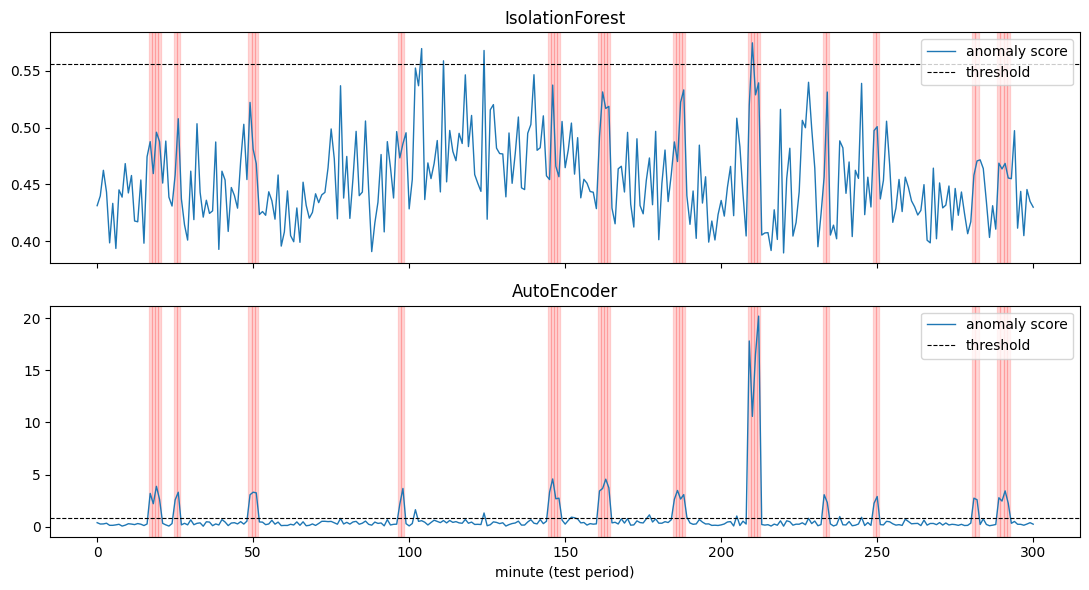

In [6]:
fig, axes = plt.subplots(len(detectors), 1, figsize=(11, 6), sharex=True)
results = {}

for ax, (name, det) in zip(axes, detectors.items()):
    s_train, s_test = det.score(X_train), det.score(X_test)
    threshold = np.percentile(s_train, 99)
    pred = (s_test > threshold).astype(int)
    results[name] = (s_test, pred, threshold)

    print(f"===== {name} (threshold={threshold:.4f}) =====")
    if y_test is not None:
        print(f"ROC-AUC: {roc_auc_score(y_test, s_test):.3f}")
        print(classification_report(y_test, pred, target_names=["normal", "anomaly"], zero_division=0))
        for i, label in enumerate(y_test):
            if label:
                ax.axvspan(i - 0.5, i + 0.5, color="red", alpha=0.15)
    ax.plot(s_test, lw=1, label="anomaly score")
    ax.axhline(threshold, color="k", ls="--", lw=0.8, label="threshold")
    ax.set_title(name)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("minute (test period)")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "scores.png"), dpi=130)
plt.show()

## ۷) تحلیل نتیجه

- **Autoencoder** تقریباً همه‌ی ناهنجاری‌ها را پیدا می‌کند، چون هر ویژگی را بازسازی می‌کند و مقدار غیرعادی خطای بزرگ می‌دهد.
- **Isolation Forest** ضعیف‌تر است: هر سه ناهنجاری الگوهایی می‌سازند که در آموزش دیده نشده‌اند و در ستون `unknown_count` جمع می‌شوند.
  این ستون در آموزش همیشه صفر است و درخت‌ها فقط داخل بازه‌ی دیده‌شده برش می‌زنند، پس نمی‌توانند از آن برای تفکیک استفاده کنند (ضعف در برون‌یابی).
- نتیجه‌ی عالی روی داده‌ی مصنوعی تضمین‌کننده‌ی همان کیفیت روی لاگ واقعی نیست.

### ایده‌های توسعه
- جایگزینی regex با الگوریتم **Drain** (کتابخانه‌ی `drain3`)
- تست روی دیتاست‌های **HDFS** یا **BGL** از Loghub
- مدل ترتیبی **LSTM / DeepLog**
- پنجره‌ی لغزنده و داشبورد هشدار (FastAPI + Grafana)